# NYC Food Safety Inspection Model
*Predicting serious health-inspection failures in NYC restaurants*

## Part 3: Model Comparison

This notebook compares **five classification models**, each tuned with **grid search** and **time-ordered cross-validation**, against the baseline from [Notebook 2](02_baseline_model.ipynb). The final model, chosen on cross-validation (not on the test set), is saved for interpretation in [Notebook 4](04_interpretation_and_recommendations.ipynb).

**Steps:**
1. Load the modeling table and recreate the same time-based split as the baseline.
2. Define one preprocessing pipeline shared by all models.
3. Tune each model with `GridSearchCV` and `TimeSeriesSplit`.
4. Compare the models on the held-out test period.
5. Evaluate them at a realistic inspector capacity, select the final model and test whether the new context features help.

## 1. Setup

In [1]:
import json
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, average_precision_score, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 13})
pd.set_option("display.float_format", "{:,.3f}".format)
pd.set_option("display.max_colwidth", 80)

PROCESSED_PATH = Path("../data/processed/model_table.csv.gz")
MODELS_DIR = Path("../models")
IMAGES_DIR = Path("../images")
RANDOM_STATE = 42
CAPACITY = 0.20  # assume inspectors can visit the riskiest 20% of restaurants first
FAIL_COLOR, PASS_COLOR, GRAY = "#c0392b", "#2e86c1", "#7f8c8d"


def save_fig(fig, name):
    """Save a figure to images/ so the README can show it."""
    fig.savefig(IMAGES_DIR / f"{name}.png", bbox_inches="tight", dpi=130)

## 2. Data and time-based split

The split is identical to the baseline: the earliest 80% of routine inspections (by date) for training, the most recent 20% for testing. All models therefore face the same, realistic task: learn from the past, predict the future.

In [2]:
# Sort by date so that TimeSeriesSplit folds always train on earlier inspections
model_df = pd.read_csv(PROCESSED_PATH, parse_dates=["inspection_date"]).sort_values("inspection_date").reset_index(drop=True)
model_df["inspection_month"] = model_df["inspection_month"].astype(str)  # month as a category (seasonality)

HISTORY_FEATURES = ["prev_cycle_score", "prev_cycle_fail", "days_since_prev_cycle", "last_score", "prior_mean_score",
                    "last_n_critical", "last_had_pest", "prior_pest_visits", "prior_temperature_visits",
                    "prior_hygiene_visits", "prior_no_fpc_visits", "prior_closed_visits", "n_prior_inspections",
                    "days_since_last_inspection", "has_prior_inspection", "chain_size", "is_chain"]
CONTEXT_FEATURES = ["zip_prior_fail_rate", "rodent_complaints_zip_3m", "food_complaints_bbl_12m", "score_trend"]
NUMERIC_FEATURES = HISTORY_FEATURES + CONTEXT_FEATURES
CATEGORICAL_FEATURES = ["boro", "cuisine_group", "inspection_month", "inspection_dow"]
TARGET = "fail"

# Same split as the baseline: earliest 80% of inspection dates for training
cutoff_date = model_df["inspection_date"].quantile(0.8)
is_train = model_df["inspection_date"] < cutoff_date
X_train = model_df.loc[is_train, NUMERIC_FEATURES + CATEGORICAL_FEATURES]
X_test = model_df.loc[~is_train, NUMERIC_FEATURES + CATEGORICAL_FEATURES]
y_train, y_test = model_df.loc[is_train, TARGET], model_df.loc[~is_train, TARGET]
print(f"Train: {len(y_train):,} inspections before {cutoff_date:%d %b %Y} ({y_train.mean():.1%} fail)")
print(f"Test:  {len(y_test):,} inspections from {cutoff_date:%d %b %Y} ({y_test.mean():.1%} fail)")
print(f"Features: {len(NUMERIC_FEATURES)} numeric ({len(CONTEXT_FEATURES)} new context features) + {len(CATEGORICAL_FEATURES)} categorical")

Train: 36,774 inspections before 06 Apr 2026 (17.3% fail)
Test:  9,226 inspections from 06 Apr 2026 (21.3% fail)
Features: 21 numeric (4 new context features) + 4 categorical


## 3. Evaluation metric (recap)

The same metric as the baseline, for the same reasons:

* **Primary metric: PR-AUC (average precision).** Only about 1 in 5 inspections is a serious failure, so accuracy is misleading (predicting "pass" for everyone scores 79–83%). Inspectors would work from a **ranked list**, and PR-AUC measures how well real failures are concentrated at the top of that list. A random ranking scores about the failure rate (≈ 0.21 on the test period).
* **Business view: performance at inspector capacity.** If inspectors can visit the riskiest **20%** of restaurants first, how many serious failures do they find (recall), and how many of those visits find a failure (precision, or "hit rate")?

Models are **tuned and selected on cross-validated PR-AUC** from the training period only. The test period is used once, at the end, to report honest performance.

## 4. Shared preprocessing

Every model uses the same preprocessing, so differences in results come from the models themselves:
* Numeric: median imputation with "was missing" flags (missing history means a new restaurant), then standardization. Scaling matters for logistic regression and k-nearest neighbors; tree models are unaffected by it.
* Categorical: "Unknown" for missing values, then one-hot encoding.

In [3]:
def make_preprocessor(numeric_features):
    """Imputation, scaling and one-hot encoding, learned from the training folds only."""
    numeric = Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)),
                        ("scale", StandardScaler())])
    categorical = Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="Unknown")),
                            ("encode", OneHotEncoder(handle_unknown="ignore"))])
    return ColumnTransformer([("num", numeric, numeric_features), ("cat", categorical, CATEGORICAL_FEATURES)])

## 5. Models and hyperparameter grids

| Model | Why it is a candidate | Hyperparameters searched |
|---|---|---|
| Logistic regression | Simple, explainable; the baseline's model, now with the context features and tuned | Regularization strength `C`, class weighting |
| k-nearest neighbors | Flags restaurants that look like past failures | Number of neighbors, distance weighting |
| Decision tree | Produces human-readable rules | Maximum depth, minimum samples per leaf |
| Random forest | Many trees averaged: captures interactions, resists overfitting | Tree depth, minimum leaf size, features per split |
| Gradient boosting | Trees built one after another to fix earlier mistakes; often the strongest on tabular data | Learning rate, tree depth, number of trees |

Grids are kept moderate so the whole notebook runs in a few minutes. Class imbalance is handled with `class_weight="balanced"` where the model supports it; PR-AUC only depends on the *ranking* of risk scores, so it is fair across all models.

In [4]:
# Each entry: (model, hyperparameter grid). "model__" targets the model step inside the pipeline
model_specs = {
    "Logistic regression": (
        LogisticRegression(max_iter=3000, random_state=RANDOM_STATE),
        {"model__C": [0.01, 0.1, 1.0, 10.0], "model__class_weight": [None, "balanced"]}),
    "k-nearest neighbors": (
        KNeighborsClassifier(),
        {"model__n_neighbors": [25, 75, 151], "model__weights": ["uniform", "distance"]}),
    "Decision tree": (
        DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE),
        {"model__max_depth": [4, 6, 8, 12], "model__min_samples_leaf": [50, 200]}),
    "Random forest": (
        RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample", n_jobs=-1, random_state=RANDOM_STATE),
        {"model__max_depth": [8, 14], "model__min_samples_leaf": [20, 50], "model__max_features": ["sqrt", 0.3]}),
    "Gradient boosting": (
        HistGradientBoostingClassifier(max_iter=300, random_state=RANDOM_STATE),
        {"model__learning_rate": [0.03, 0.1], "model__max_depth": [3, 6], "model__l2_regularization": [0.0, 1.0]}),
}

## 6. Grid search with time-ordered cross-validation

`TimeSeriesSplit` with 5 folds: each fold trains on earlier inspections and validates on the period right after, never the other way round. A normal shuffled k-fold would let models peek at the future and overstate performance.

In [5]:
# 5 expanding-window folds: train on earlier data, validate on the next period
cv = TimeSeriesSplit(n_splits=5)
searches, cv_rows = {}, []
for name, (estimator, grid) in model_specs.items():
    pipeline = Pipeline([("prep", make_preprocessor(NUMERIC_FEATURES)), ("model", estimator)])
    search = GridSearchCV(pipeline, grid, cv=cv, scoring={"pr_auc": "average_precision", "roc_auc": "roc_auc"},
                          refit="pr_auc", n_jobs=-1)
    # Try every combination in the grid; refit the best one on the full training period
    start = time.time()
    search.fit(X_train, y_train)
    best = search.best_index_
    searches[name] = search
    cv_rows.append({"model": name,
                    "cv PR-AUC": search.cv_results_["mean_test_pr_auc"][best],
                    "cv PR-AUC std": search.cv_results_["std_test_pr_auc"][best],
                    "cv ROC-AUC": search.cv_results_["mean_test_roc_auc"][best],
                    "combinations tried": len(search.cv_results_["params"]),
                    "search time (s)": time.time() - start,
                    "best hyperparameters": {k.replace("model__", ""): v for k, v in search.best_params_.items()}})
    print(f"{name:<22} cv PR-AUC {cv_rows[-1]['cv PR-AUC']:.3f}  ({time.time() - start:.0f}s)")

cv_results = pd.DataFrame(cv_rows).set_index("model").sort_values("cv PR-AUC", ascending=False)
cv_results

Logistic regression    cv PR-AUC 0.302  (2s)


k-nearest neighbors    cv PR-AUC 0.286  (2s)


Decision tree          cv PR-AUC 0.273  (1s)


Random forest          cv PR-AUC 0.307  (13s)


Gradient boosting      cv PR-AUC 0.302  (5s)


,cv PR-AUC,cv PR-AUC std,cv ROC-AUC,combinations tried,search time (s),best hyperparameters
model,,,,,,
Random forest,0.307,0.039,0.673,8,13.103,"{'max_depth': 14, 'max_features': 'sqrt', 'min_samples_leaf': 20}"
Logistic regression,0.302,0.048,0.666,8,2.151,"{'C': 0.01, 'class_weight': None}"
Gradient boosting,0.302,0.040,0.668,8,5.332,"{'l2_regularization': 0.0, 'learning_rate': 0.03, 'max_depth': 3}"
k-nearest neighbors,0.286,0.039,0.651,6,1.739,"{'n_neighbors': 151, 'weights': 'distance'}"
Decision tree,0.273,0.037,0.650,8,0.792,"{'max_depth': 8, 'min_samples_leaf': 200}"


For reference, the **baseline** from Notebook 2 (logistic regression, history features only, no tuning) is cross-validated the same way:

In [6]:
baseline = Pipeline([("prep", make_preprocessor(HISTORY_FEATURES)),
                     ("model", LogisticRegression(class_weight="balanced", max_iter=3000, random_state=RANDOM_STATE))])
# A one-point "grid" reuses GridSearchCV purely to get the same cross-validated scores
baseline_search = GridSearchCV(baseline, {"model__C": [1.0]}, cv=cv,
                               scoring={"pr_auc": "average_precision", "roc_auc": "roc_auc"}, refit="pr_auc")
baseline_search.fit(X_train, y_train)
print(f"Baseline cv PR-AUC: {baseline_search.cv_results_['mean_test_pr_auc'][0]:.3f} "
      f"± {baseline_search.cv_results_['std_test_pr_auc'][0]:.3f}")

Baseline cv PR-AUC: 0.297 ± 0.046


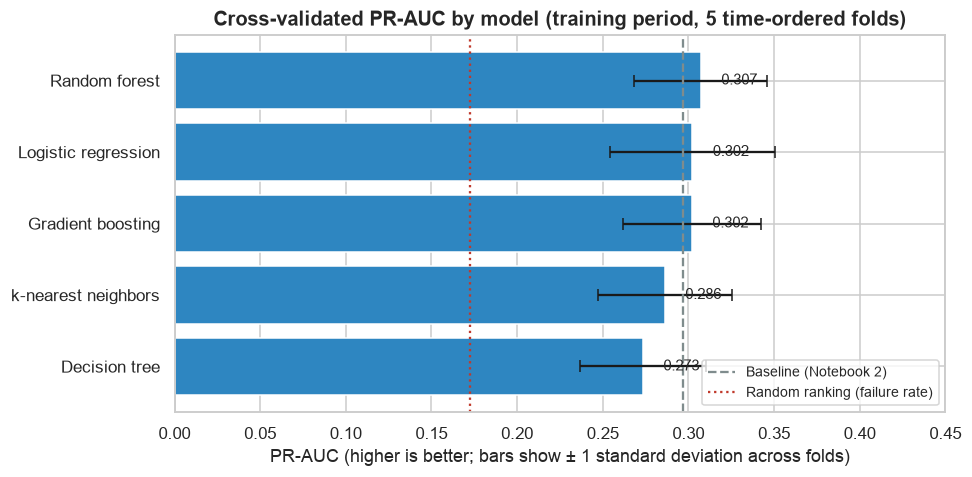

In [7]:
fig, ax = plt.subplots(figsize=(9, 4.5))
plot_cv = cv_results.sort_values("cv PR-AUC")
ax.barh(plot_cv.index, plot_cv["cv PR-AUC"], xerr=plot_cv["cv PR-AUC std"], color=PASS_COLOR, capsize=4)
ax.axvline(baseline_search.cv_results_["mean_test_pr_auc"][0], color=GRAY, ls="--", lw=1.5, label="Baseline (Notebook 2)")
ax.axvline(y_train.mean(), color=FAIL_COLOR, ls=":", lw=1.5, label="Random ranking (failure rate)")
for i, v in enumerate(plot_cv["cv PR-AUC"]):
    ax.text(v + 0.012, i, f"{v:.3f}", va="center", fontsize=10)
ax.set(title="Cross-validated PR-AUC by model (training period, 5 time-ordered folds)",
       xlabel="PR-AUC (higher is better; bars show ± 1 standard deviation across folds)", xlim=(0, 0.45))
ax.legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()

**Observations:**
* Every tuned model clearly beats a random ranking (0.17 on the training period).
* The three strongest models finish almost level: **random forest 0.307, logistic regression 0.302 and gradient boosting 0.302**, against **0.297** for the untuned baseline. The gaps between them (0.005) are much smaller than the fold-to-fold variation (± 0.04), so they are **statistically indistinguishable**.
* A single decision tree (0.273) and k-nearest neighbors (0.286) are clearly weaker: one tree is too coarse, and distance-based neighbors struggle with dozens of mixed features.
* Tuning chose strong regularization for logistic regression (`C = 0.01`), shallow trees for gradient boosting (depth 3, slow learning rate) and large leaves for the forest. All point the same way: the signal is real but modest, and models that try to learn fine detail start fitting noise.

## 7. Performance on the test period

Each model is refit on the full training period with its best hyperparameters (done automatically by `GridSearchCV`) and scored once on the six most recent months.

In [8]:
def at_capacity(y_true, scores, share=CAPACITY):
    """Flag exactly the riskiest `share` of inspections; return recall (failures found) and precision (hit rate)."""
    # Rank and take the top k, so tied scores never push the list above inspector capacity
    k = int(round(len(scores) * share))
    flagged = np.zeros(len(scores), dtype=int)
    flagged[np.argsort(-scores, kind="stable")[:k]] = 1
    return recall_score(y_true, flagged), precision_score(y_true, flagged), flagged


# Risk scores (probability of a serious failure) for every test inspection, per model
test_scores = {"Baseline (Notebook 2)": baseline_search.predict_proba(X_test)[:, 1]}
test_scores.update({name: search.predict_proba(X_test)[:, 1] for name, search in searches.items()})
test_rows = []
for name, scores in test_scores.items():
    recall, precision, _ = at_capacity(y_test, scores)
    test_rows.append({"model": name, "test PR-AUC": average_precision_score(y_test, scores),
                      "test ROC-AUC": roc_auc_score(y_test, scores),
                      f"failures found (top {CAPACITY:.0%})": recall, f"hit rate (top {CAPACITY:.0%})": precision})
test_results = pd.DataFrame(test_rows).set_index("model").sort_values("test PR-AUC", ascending=False)
test_results

,test PR-AUC,test ROC-AUC,failures found (top 20%),hit rate (top 20%)
model,,,,
Logistic regression,0.357,0.676,0.353,0.376
Baseline (Notebook 2),0.355,0.676,0.350,0.372
Gradient boosting,0.354,0.676,0.359,0.383
Random forest,0.348,0.673,0.346,0.368
k-nearest neighbors,0.325,0.651,0.329,0.351
Decision tree,0.316,0.645,0.330,0.351


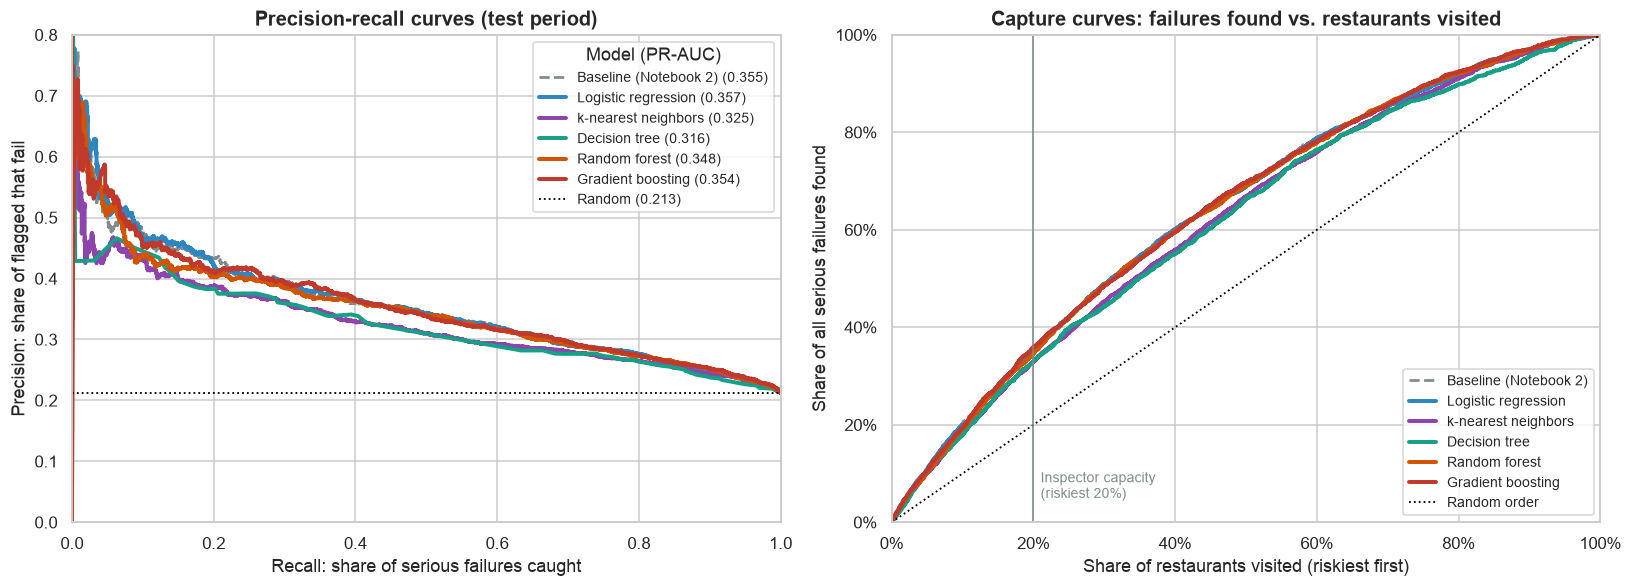

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
palette = dict(zip(test_scores, ["#7f8c8d", "#2e86c1", "#8e44ad", "#16a085", "#d35400", "#c0392b"]))
shares = np.linspace(0.005, 1, 200)
for name, scores in test_scores.items():
    precision, recall, _ = precision_recall_curve(y_test, scores)
    lw, ls = (2.6, "-") if name != "Baseline (Notebook 2)" else (1.8, "--")
    axes[0].plot(recall, precision, color=palette[name], lw=lw, ls=ls, label=f"{name} ({average_precision_score(y_test, scores):.3f})")
    # Capture curve: cumulative share of failures found when visiting in risk order
    order = np.argsort(-scores)
    found = np.cumsum(y_test.to_numpy()[order]) / y_test.sum()
    axes[1].plot(np.arange(1, len(scores) + 1) / len(scores), found, color=palette[name], lw=lw, ls=ls, label=name)
axes[0].axhline(y_test.mean(), color="black", ls=":", lw=1.2, label=f"Random ({y_test.mean():.3f})")
axes[0].set(title="Precision-recall curves (test period)", xlabel="Recall: share of serious failures caught",
            ylabel="Precision: share of flagged that fail", xlim=(0, 1), ylim=(0, 0.8))
axes[0].legend(title="Model (PR-AUC)", fontsize=9, loc="upper right")
axes[1].plot([0, 1], [0, 1], color="black", ls=":", lw=1.2, label="Random order")
axes[1].axvline(CAPACITY, color=GRAY, lw=1)
axes[1].text(CAPACITY + 0.01, 0.05, f"Inspector capacity\n(riskiest {CAPACITY:.0%})", fontsize=9, color=GRAY)
axes[1].set(title="Capture curves: failures found vs. restaurants visited", xlabel="Share of restaurants visited (riskiest first)",
            ylabel="Share of all serious failures found", xlim=(0, 1), ylim=(0, 1))
axes[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[1].legend(fontsize=9, loc="lower right")
plt.tight_layout()
save_fig(fig, "model_comparison_curves")
plt.show()

## 8. Errors at inspector capacity: confusion matrices

Each model flags its riskiest 20% of test inspections. The matrices show what that means: **true positives** are failing restaurants visited first, **false negatives** are failing restaurants left for later, and **false positives** are visits to restaurants that turned out fine.

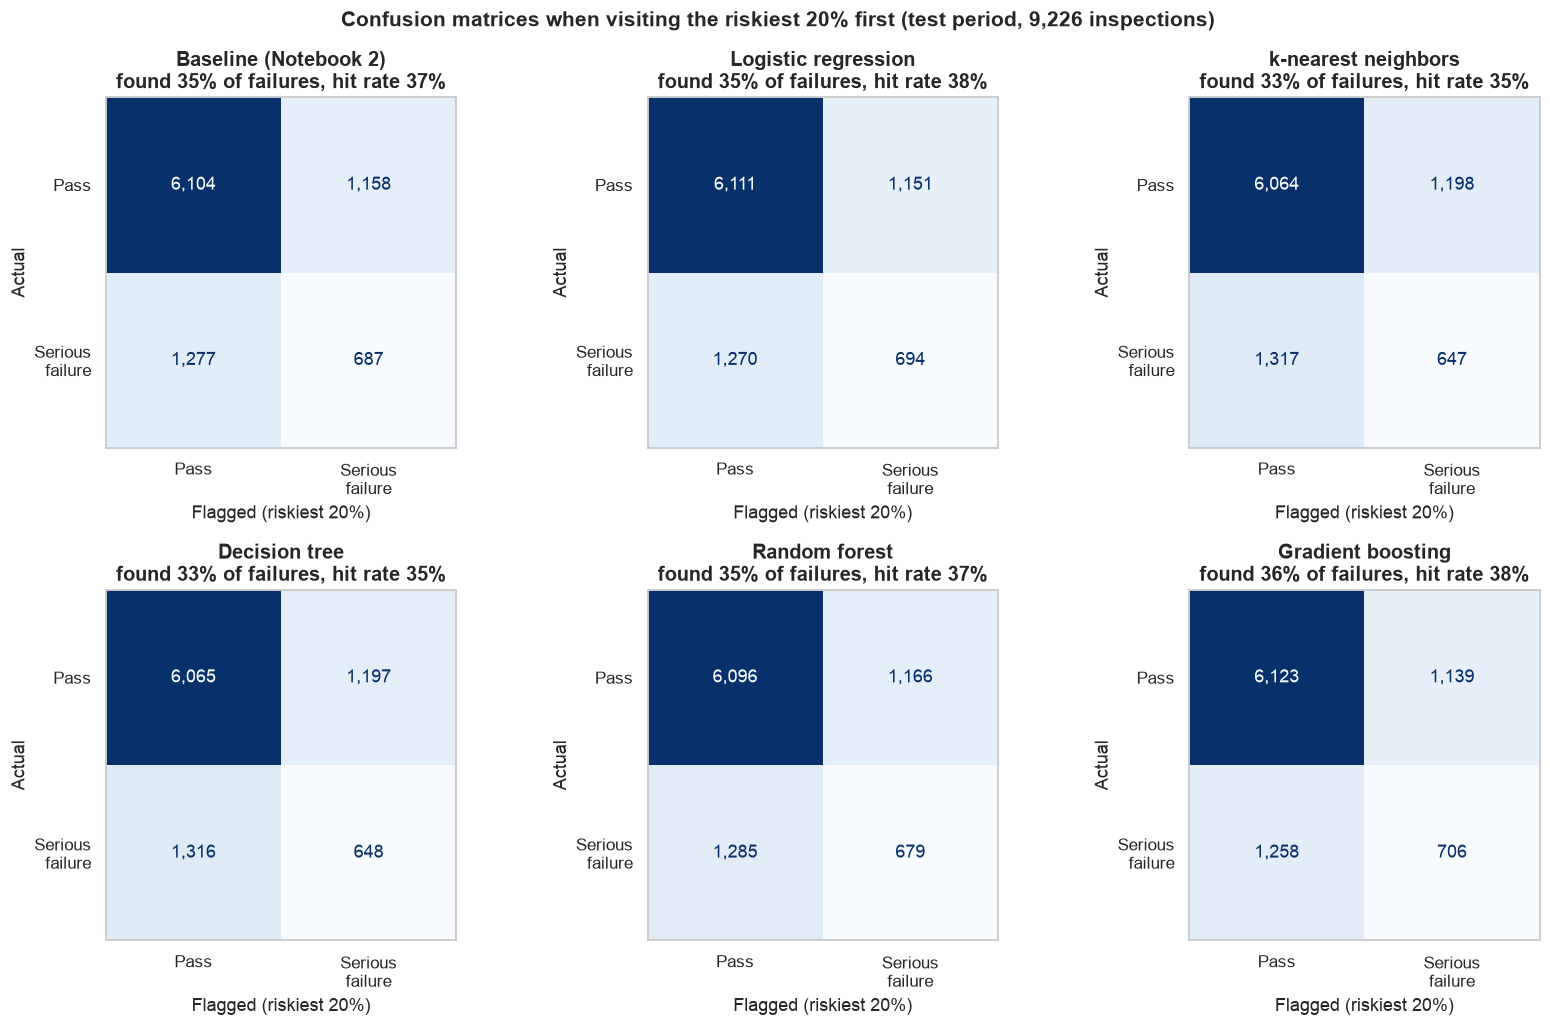

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9.5))
for ax, (name, scores) in zip(axes.flat, test_scores.items()):
    recall, precision, flagged = at_capacity(y_test, scores)
    ConfusionMatrixDisplay.from_predictions(y_test, flagged, display_labels=["Pass", "Serious\nfailure"], cmap="Blues",
                                            values_format=",", ax=ax, colorbar=False)
    ax.set(title=f"{name}\nfound {recall:.0%} of failures, hit rate {precision:.0%}", xlabel="Flagged (riskiest 20%)", ylabel="Actual")
    ax.grid(False)
fig.suptitle(f"Confusion matrices when visiting the riskiest {CAPACITY:.0%} first (test period, {len(y_test):,} inspections)",
             fontweight="bold", fontsize=14)
plt.tight_layout()
plt.show()

**Observations on the test period (April to October 2026):**
* The ranking of models is the same story: **logistic regression 0.357, baseline 0.355, gradient boosting 0.354, random forest 0.348**, then k-nearest neighbors (0.325) and the decision tree (0.316).
* At inspector capacity, the best models find about **35–36% of all serious failures** while visiting 20% of restaurants, and **37–38% of those visits** uncover a serious failure, against **21%** for random visits.
* The more complex models (random forest, gradient boosting) **do not beat** a well-regularized logistic regression. The limit is the information in the data, not the choice of algorithm.

## 9. Model selection: the one-standard-error rule

When several models score within the noise of each other, picking the single highest score mostly rewards luck. The **one-standard-error rule** is a standard remedy: take the best cross-validated PR-AUC, compute its standard error across the 5 folds, and choose the **simplest** model whose score is within that margin. Simpler here means easier to explain and audit: logistic regression, then decision tree, k-nearest neighbors, gradient boosting and random forest.

In [11]:
SIMPLICITY_ORDER = ["Logistic regression", "Decision tree", "k-nearest neighbors", "Gradient boosting", "Random forest"]
top = cv_results.iloc[0]
standard_error = top["cv PR-AUC std"] / np.sqrt(cv.get_n_splits())
eligible = cv_results[cv_results["cv PR-AUC"] >= top["cv PR-AUC"] - standard_error].index
best_name = next(name for name in SIMPLICITY_ORDER if name in eligible)
best_search = searches[best_name]
print(f"Best cv PR-AUC: {top['cv PR-AUC']:.3f} ({top.name}); one standard error = {standard_error:.3f}")
print(f"Models within one standard error: {', '.join(eligible)}")
print(f"Selected (simplest eligible): {best_name} with {cv_results.loc[best_name, 'best hyperparameters']}")

Best cv PR-AUC: 0.307 (Random forest); one standard error = 0.017
Models within one standard error: Random forest, Logistic regression, Gradient boosting
Selected (simplest eligible): Logistic regression with {'C': 0.01, 'class_weight': None}


## 10. Do the new context features help?

The selected model is re-run without the four context features (ZIP-code failure history, rodent complaints, building complaints, score trend), using the same tuned hyperparameters and the same cross-validation.

In [12]:
# Same model and settings, but only the history features
ablation = Pipeline([("prep", make_preprocessor(HISTORY_FEATURES)), ("model", best_search.best_estimator_.named_steps["model"])])
ablation_search = GridSearchCV(ablation, {}, cv=cv, scoring="average_precision").fit(X_train, y_train)
ablation_scores = ablation_search.predict_proba(X_test)[:, 1]
ablation_table = pd.DataFrame({
    "cv PR-AUC": [cv_results.loc[best_name, "cv PR-AUC"], ablation_search.best_score_],
    "test PR-AUC": [average_precision_score(y_test, test_scores[best_name]), average_precision_score(y_test, ablation_scores)],
    f"failures found (top {CAPACITY:.0%})": [at_capacity(y_test, test_scores[best_name])[0], at_capacity(y_test, ablation_scores)[0]],
}, index=[f"{best_name}: all features", f"{best_name}: without context features"])
ablation_table

,cv PR-AUC,test PR-AUC,failures found (top 20%)
Logistic regression: all features,0.302,0.357,0.353
Logistic regression: without context features,0.299,0.354,0.353


**Observations:** the context features improve the selected model only slightly (cross-validated PR-AUC 0.302 vs 0.299; test 0.357 vs 0.354), and the number of failures found at capacity is unchanged (35% either way). ZIP-code failure history and 311 complaints are real signals (Notebook 1), but most of what they say is **already captured by the restaurant's own inspection history**: restaurants in high-failure ZIP codes tend to have poor records themselves. They are kept in the final model because they cost nothing to compute from public data and help a little, but they are not a breakthrough.

## 11. Save the final model

In [13]:
MODELS_DIR.mkdir(exist_ok=True)
# Save the fitted pipeline (preprocessing + model) and its settings for Notebook 4
joblib.dump(best_search.best_estimator_, MODELS_DIR / "best_model.joblib")
with open(MODELS_DIR / "best_model_info.json", "w") as f:
    json.dump({"model": best_name, "best_hyperparameters": cv_results.loc[best_name, "best hyperparameters"],
               "numeric_features": NUMERIC_FEATURES, "categorical_features": CATEGORICAL_FEATURES,
               "train_cutoff_date": f"{cutoff_date:%Y-%m-%d}", "cv_pr_auc": round(float(cv_results.loc[best_name, "cv PR-AUC"]), 4),
               "test_pr_auc": round(float(test_results.loc[best_name, "test PR-AUC"]), 4)}, f, indent=2, default=str)
print(f"Selected model: {best_name} (one-standard-error rule) -> saved to {MODELS_DIR / 'best_model.joblib'}")

Selected model: Logistic regression (one-standard-error rule) -> saved to ../models/best_model.joblib


**Final model: tuned logistic regression** (`C = 0.01`, i.e., strong regularization, no class weighting), using all 21 numeric and 4 categorical features.

* Random forest had the highest cross-validated PR-AUC (0.307), but logistic regression (0.302) and gradient boosting (0.302) are within one standard error (0.017), so the simplest of the three is chosen.
* On the untouched test period it is also the top performer: **PR-AUC 0.357, ROC-AUC 0.676**, finding **35% of serious failures** when visiting the riskiest 20% of restaurants, with a **38% hit rate** against 21% at random.
* It is fully explainable: every risk factor has a direction and size that can be shown to inspectors and restaurant owners, which matters for a public agency.

[Notebook 4](04_interpretation_and_recommendations.ipynb) interprets this model and turns the results into recommendations.